# DAY 40 : DESCRIPTIVE STATISTICS AND CENTRAL TENDENCY

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("superstore.csv" , encoding="latin1")
print("Dataset Shape :" , df.shape)

Dataset Shape : (9994, 14)


In [8]:
print("\nFirst Five records :")
display(df.head())


First Five records :


,Order ID,Order Date,Customer Name,Segment,Country,City,State,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,CA-2016-152156,11-08-2016,Claire Gute,Consumer,United States,Henderson,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,CA-2016-152156,11-08-2016,Claire Gute,Consumer,United States,Henderson,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,CA-2016-138688,06-12-2016,Darrin Van Huff,Corporate,United States,Los Angeles,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,US-2015-108966,10-11-2015,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,US-2015-108966,10-11-2015,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [9]:
print("Datset Information :")
display(df.info())

Datset Information :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       9994 non-null   object 
 1   Order Date     9994 non-null   object 
 2   Customer Name  9994 non-null   object 
 3   Segment        9994 non-null   object 
 4   Country        9994 non-null   object 
 5   City           9994 non-null   object 
 6   State          9994 non-null   object 
 7   Region         9994 non-null   object 
 8   Category       9994 non-null   object 
 9   Sub-Category   9994 non-null   object 
 10  Sales          9994 non-null   float64
 11  Quantity       9994 non-null   int64  
 12  Discount       9994 non-null   float64
 13  Profit         9994 non-null   float64
dtypes: float64(3), int64(1), object(10)
memory usage: 1.1+ MB


None

In [10]:
print("Numerical Descriptive Statistics :")
display(df.describe())

Numerical Descriptive Statistics :


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [13]:
print("Check Missing Values :")
display(df.isnull().sum().sum())

Check Missing Values :


0

In [12]:
print("Checking for duplicates :")
display(df.duplicated().sum())

Checking for duplicates :


1

In [16]:
print("Total Sales :" , round(df["Sales"].sum() , 2))
print("Average Sales :" , round(df["Sales"].mean() , 2))
print("Total Orders :" , df["Order ID"].nunique())
print("Total Customers : " , df["Customer Name"].nunique())
print("Average Quantity : " , round(df["Quantity"].mean() , 2))
print("Average Profit :" , round(df["Profit"].mean() , 2))

Total Sales : 2297200.86
Average Sales : 229.86
Total Orders : 5009
Total Customers :  793
Average Quantity :  3.79
Average Profit : 28.66


## MEASURE IF CENTRAL TENDENCY

In [21]:
print("Rows Before cleaning :"  , len(df))

df = df.drop_duplicates().copy()

print("Rows After cleaning :" , len(df))
print("Remaining Duplicate :" , df.duplicated().sum())

Rows Before cleaning : 9994
Rows After cleaning : 9993
Remaining Duplicate : 0


In [22]:
numeric_cols = ["Sales", "Quantity", "Profit"]
mean_values = df[numeric_cols].mean()
median_values = df[numeric_cols].median()
mode_values = {
    col: df[col].mode().tolist()
    for col in numeric_cols
}

In [23]:

central_tendency = pd.DataFrame({
    "Mean": mean_values,
    "Median": median_values,
    "Mode": [
        df[col].mode().iloc[0]
        for col in numeric_cols
    ]
})

In [24]:
print("\nCENTRAL TENDENCY SUMMARY:")
display(central_tendency.round(2))


CENTRAL TENDENCY SUMMARY:


,Mean,Median,Mode
Sales,229.85,54.48,12.96
Quantity,3.79,3.00,3.00
Profit,28.66,8.67,0.00


In [25]:
# DISPLAY ALL MODE VALUES

print("\nALL MODE VALUES:")

for column, values in mode_values.items():
    print(f"{column}: {values}")


# COMPARE MEAN AND MEDIAN

print("\nMEAN VS MEDIAN COMPARISON:")

for column in numeric_cols:
    mean = mean_values[column]
    median = median_values[column]

    print(f"\n{column}")
    print("Mean:", round(mean, 2))
    print("Median:", round(median, 2))

    if mean > median:
        print("Observation: Mean is greater than Median.")
    elif mean < median:
        print("Observation: Mean is less than Median.")
    else:
        print("Observation: Mean and Median are equal.")


# BUSINESS SUMMARY

print("\n========== BUSINESS SUMMARY ==========")

print("Average Order Sales:", round(mean_values["Sales"], 2))

print("Typical Order Sales:", round(median_values["Sales"], 2))

print("Most Common Order Quantity:",
      mode_values["Quantity"])

print("Average Profit:", round(mean_values["Profit"], 2))

print("Typical Profit:", round(median_values["Profit"], 2))


ALL MODE VALUES:
Sales: [12.96]
Quantity: [3]
Profit: [0.0]

MEAN VS MEDIAN COMPARISON:

Sales
Mean: 229.85
Median: 54.48
Observation: Mean is greater than Median.

Quantity
Mean: 3.79
Median: 3.0
Observation: Mean is greater than Median.

Profit
Mean: 28.66
Median: 8.67
Observation: Mean is greater than Median.

========== BUSINESS SUMMARY ==========
Average Order Sales: 229.85
Typical Order Sales: 54.48
Most Common Order Quantity: [3]
Average Profit: 28.66
Typical Profit: 8.67


## DISPERSION AND DISTRIBUTION ANALYSIS

STATISTICAL DISPERSION SUMMARY:


,Range,Variance,Std_Deviation,Q1,Median,Q3,IQR,Skewness
Sales,22638.04,388473.06,623.28,17.28,54.48,209.94,192.66,12.97
Quantity,13.00,4.95,2.23,2.00,3.00,5.00,3.00,1.28
Profit,14999.95,54883.12,234.27,1.73,8.67,29.36,27.63,7.56



OUTLIER ANALYSIS:


,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
Sales,-271.71,498.93,1167.0,11.68
Quantity,-2.50,9.50,170.0,1.70
Profit,-39.72,70.81,1881.0,18.82


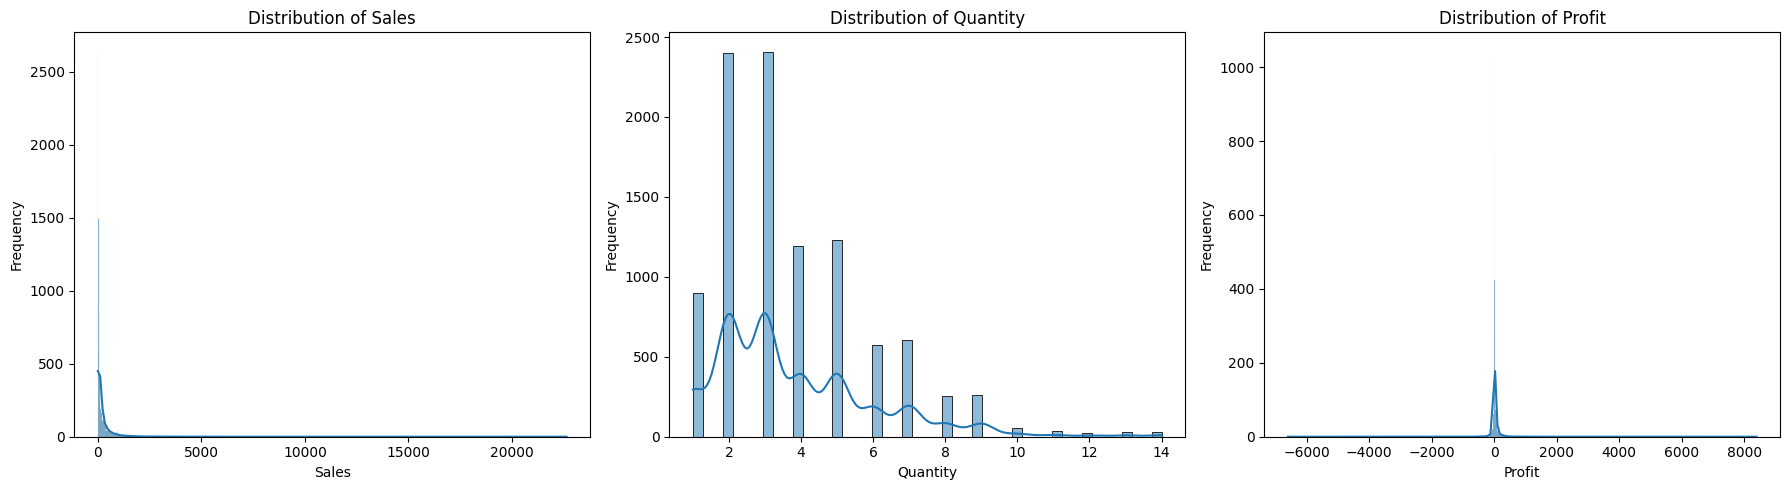

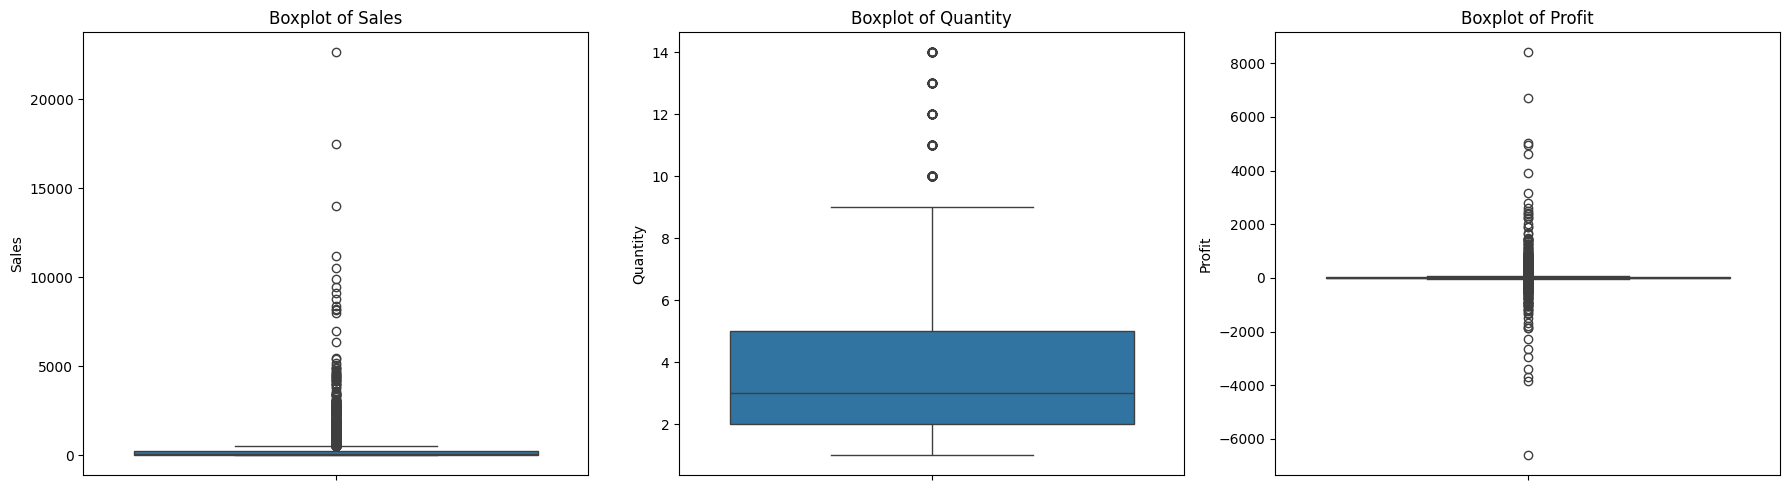


========== BUSINESS INTERPRETATION ==========

Sales
Standard Deviation: 623.28
IQR: 192.66
Skewness: 12.97
Outliers: 1167
Distribution: Positively Skewed

Quantity
Standard Deviation: 2.23
IQR: 3.0
Skewness: 1.28
Outliers: 170
Distribution: Positively Skewed

Profit
Standard Deviation: 234.27
IQR: 27.63
Skewness: 7.56
Outliers: 1881
Distribution: Positively Skewed


In [26]:

# 1. SELECT NUMERICAL COLUMNS

numeric_cols = ["Sales", "Quantity", "Profit"]


# 2. CALCULATE RANGE

range_values = df[numeric_cols].max() - df[numeric_cols].min()


# 3. CALCULATE VARIANCE

variance_values = df[numeric_cols].var()


# 4. CALCULATE STANDARD DEVIATION

std_values = df[numeric_cols].std()


# 5. CALCULATE QUARTILES AND IQR

q1 = df[numeric_cols].quantile(0.25)

q2 = df[numeric_cols].quantile(0.50)

q3 = df[numeric_cols].quantile(0.75)

iqr = q3 - q1


# 6. CALCULATE SKEWNESS

skew_values = df[numeric_cols].skew()


# 7. CREATE STATISTICAL SUMMARY

dispersion_summary = pd.DataFrame({
    "Range": range_values,
    "Variance": variance_values,
    "Std_Deviation": std_values,
    "Q1": q1,
    "Median": q2,
    "Q3": q3,
    "IQR": iqr,
    "Skewness": skew_values
})

print("STATISTICAL DISPERSION SUMMARY:")

display(dispersion_summary.round(2))


# 8. DETECT OUTLIERS USING IQR

outlier_results = {}

for col in numeric_cols:

    lower_bound = q1[col] - 1.5 * iqr[col]

    upper_bound = q3[col] + 1.5 * iqr[col]

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results[col] = {
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (
            len(outliers) / len(df)
        ) * 100
    }


outlier_summary = pd.DataFrame(outlier_results).T

print("\nOUTLIER ANALYSIS:")

display(outlier_summary.round(2))


# 9. HISTOGRAMS

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, col in zip(axes, numeric_cols):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")

    ax.set_xlabel(col)

    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# 10. BOXPLOTS

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, col in zip(axes, numeric_cols):

    sns.boxplot(
        data=df,
        y=col,
        ax=ax
    )

    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()


# 11. FINAL BUSINESS SUMMARY

print("\n========== BUSINESS INTERPRETATION ==========")

for col in numeric_cols:

    print(f"\n{col}")

    print("Standard Deviation:",
          round(std_values[col], 2))

    print("IQR:",
          round(iqr[col], 2))

    print("Skewness:",
          round(skew_values[col], 2))

    print("Outliers:",
          outlier_results[col]["Outlier Count"])

    if skew_values[col] > 0:
        print("Distribution: Positively Skewed")

    elif skew_values[col] < 0:
        print("Distribution: Negatively Skewed")

    else:
        print("Distribution: Approximately Symmetrical")

In [27]:

# 1. CREATE FINAL STATISTICAL SUMMARY

final_summary = pd.DataFrame({
    "Mean": df[["Sales", "Quantity", "Profit"]].mean(),
    "Median": df[["Sales", "Quantity", "Profit"]].median(),
    "Mode": [
        df[col].mode().iloc[0]
        for col in ["Sales", "Quantity", "Profit"]
    ],
    "Std_Deviation": df[
        ["Sales", "Quantity", "Profit"]
    ].std(),
    "Skewness": df[
        ["Sales", "Quantity", "Profit"]
    ].skew()
})

print("FINAL STATISTICAL SUMMARY:")
display(final_summary.round(2))


# 2. CALCULATE SALES OUTLIER PERCENTAGE

sales_outlier_count = int(
    outlier_results["Sales"]["Outlier Count"]
)

profit_outlier_count = int(
    outlier_results["Profit"]["Outlier Count"]
)

quantity_outlier_count = int(
    outlier_results["Quantity"]["Outlier Count"]
)

total_records = len(df)

print("\nOUTLIER PERCENTAGES:")

for col in ["Sales", "Quantity", "Profit"]:
    count = outlier_results[col]["Outlier Count"]
    percentage = (count / total_records) * 100

    print(
        f"{col}: {count} records "
        f"({percentage:.2f}%)"
    )


# 3. IDENTIFY HIGHEST VARIABILITY

highest_variability = std_values.idxmax()

print("\nHighest Standard Deviation:",
      highest_variability)


# 4. IDENTIFY MOST SKEWED VARIABLE

most_skewed = skew_values.abs().idxmax()

print("Most Skewed Variable:", most_skewed)


# 5. BUSINESS INTERPRETATION

print("\n========== FINAL BUSINESS INSIGHTS ==========")

print(
    "Average Order Sales:",
    round(mean_values["Sales"], 2)
)

print(
    "Median Order Sales:",
    round(median_values["Sales"], 2)
)

print(
    "Average Profit:",
    round(mean_values["Profit"], 2)
)

print(
    "Median Profit:",
    round(median_values["Profit"], 2)
)

print(
    "Sales Outliers:",
    sales_outlier_count
)

print(
    "Profit Outliers:",
    profit_outlier_count
)

print(
    "Quantity Outliers:",
    quantity_outlier_count
)


# 6. FINAL DATA QUALITY VALIDATION

print("\n========== FINAL VALIDATION ==========")

print("Dataset Shape:", df.shape)

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("Total Sales:", round(df["Sales"].sum(), 2))

print("Total Profit:", round(df["Profit"].sum(), 2))

FINAL STATISTICAL SUMMARY:


,Mean,Median,Mode,Std_Deviation,Skewness
Sales,229.85,54.48,12.96,623.28,12.97
Quantity,3.79,3.00,3.00,2.23,1.28
Profit,28.66,8.67,0.00,234.27,7.56



OUTLIER PERCENTAGES:
Sales: 1167 records (11.68%)
Quantity: 170 records (1.70%)
Profit: 1881 records (18.82%)

Highest Standard Deviation: Sales
Most Skewed Variable: Sales

========== FINAL BUSINESS INSIGHTS ==========
Average Order Sales: 229.85
Median Order Sales: 54.48
Average Profit: 28.66
Median Profit: 8.67
Sales Outliers: 1167
Profit Outliers: 1881
Quantity Outliers: 170

========== FINAL VALIDATION ==========
Dataset Shape: (9993, 14)
Missing Values: 0
Duplicate Rows: 0
Total Sales: 2296919.49
Total Profit: 286409.08
